# Домашнее задание  2 
RAG и память агента

In [1]:
%pip install -q requests pydantic python-dotenv pandas matplotlib numpy pymilvus pypdf

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import os, re, sys, json, time, hashlib, threading
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from pymilvus import MilvusClient
from pypdf import PdfReader

from dotenv import load_dotenv
load_dotenv(dotenv_path=Path(".env"))
assert os.getenv("OPENROUTER_API_KEY"), ("Нет ключа OPENROUTER_API_KEY в .env")


CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "X-Title": "llm-rag-homework-02"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = Path("data")
PDF_DIR = DATA / "pdf"
MILVUS_URI = os.getenv("MILVUS_URI", "http://localhost:19530")
Path("img").mkdir(exist_ok=True)


@dataclass
class Ledger:
    calls: list = field(default_factory=list)
    local: threading.local = field(default_factory=threading.local)

    def add(self, tag, model, usage, seconds=0.0):
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": usage.get("prompt_tokens", 0),
                           "completion": usage.get("completion_tokens", 0), "cost": cost, "seconds": round(seconds, 2)})
        self.local.spent = self.mine + cost
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    @property
    def mine(self):
        return getattr(self.local, "spent", 0.0)

    def table(self):
        frame = pd.DataFrame(self.calls, columns=["tag", "model", "prompt", "completion", "cost", "seconds"])
        return frame.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                                      completion=("completion", "sum"), cost=("cost", "sum")).round(5)


ledger = Ledger()


def post_with_retry(url, body, attempts=5):
    problem = "нет ответа"
    for attempt in range(attempts):
        try:
            r = requests.post(url, json=body, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            problem = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            problem = type(e).__name__
        time.sleep(2.0 * (attempt + 1))
    raise RuntimeError(problem)


def chat(messages, model, tools=None, tag="chat"):
    body = {"model": model, "messages": messages, "temperature": 0, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
    started = time.perf_counter()
    data = post_with_retry(CHAT_URL, body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]


def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

In [9]:
print("Ключ OpenRouter найден:", bool(os.getenv("OPENROUTER_API_KEY")))

Ключ OpenRouter найден: True


In [14]:
print("Milvus:", MILVUS_URI)

Milvus: http://localhost:19530


#### Загрузка pdf

In [2]:
DATA = Path("data")
PDF_DIR = DATA / "pdf"

PDF_URLS = { "1707.07435v7.pdf": "https://arxiv.org/pdf/1707.07435", "1812.02353v3.pdf": "https://arxiv.org/pdf/1812.02353",
    "2302.09178v2.pdf": "https://arxiv.org/pdf/2302.09178", "5716.pdf": "https://storage.googleapis.com/gweb-research2023-media/pubtools/5716.pdf",
    "45530.pdf": "https://research.google.com/pubs/archive/45530.pdf",
    "A_Survey_of_Neural_Recommender_Systems.pdf": "https://le-wu.com/files/Publications/JOURNAL/A_Survey_of_Neural_Recommender_Systems.pdf",
    "youtube-multitask.pdf": "https://daiwk.github.io/assets/youtube-multitask.pdf",
    "youtube_mozilla_2021.pdf": "https://assets.mofoprod.net/network/documents/Mozilla_YouTube_Regrets_Report.pdf"}


In [3]:
pdf_pages = []

for path in sorted(PDF_DIR.glob("*.pdf")):
    reader = PdfReader(str(path))

    for page_number, page in enumerate(reader.pages, start=1):
        text = page.extract_text() or ""

        if not text.strip():
            continue

        pdf_pages.append({ "page": path.name, "page_number": page_number,"section": f"Page {page_number}","url": PDF_URLS[path.name],"text": text })

print("Загружено страниц:", len(pdf_pages))
print("Всего символов:", sum(len(p["text"]) for p in pdf_pages))

could not convert string to float: b'0.00-34120734' : FloatObject (b'0.00-34120734') invalid; use 0.0 instead


Загружено страниц: 142
Всего символов: 624004


#### Нарезка документов  
1)Наивная нарезка (char_chunks) - каждые 400 символов, даже если предложение обрывается  
2)Структурная нарезка (structured_chunks) - объединяем целые предложения, пока их суммарная длина не приблизится к 400 символам. Если следующее предложение не помещается, начинаем новый чанк.  
  
Каждый фрагмент сохраняет метаданные исходного документа:название PDF, номер страницы и ссылку на источник.

**Наивная нарезка:**

In [5]:
def chunk_chars(page, size=400):
    text = " ".join(page["text"].split())
    return [{ **page, "text": text[i:i + size]} for i in range(0, len(text), size)]

char_chunks = [ chunk 
                for page in pdf_pages 
                for chunk in chunk_chars(page)]

print("Количество фрагментов:", len(char_chunks))
print("Размер первого фрагмента:", len(char_chunks[0]["text"]))
print("\nПример фрагмента:\n")
print(char_chunks[0]["text"])

Количество фрагментов: 1608
Размер первого фрагмента: 400

Пример фрагмента:

1 Deep Learning based Recommender System: A Survey and New Perspectives SHUAI ZHANG, University of New South Wales LINA YAO, University of New South Wales AIXIN SUN, Nanyang Technological University YI TAY, Nanyang Technological University With the ever-growing volume of online information, recommender systems have been an eﬀective strategy to overcome such information overload. /T_he utility of r


**Структурная нарезка:**

In [6]:
def chunk_structured(page, size=400):
    text = page["text"]
    text = re.sub( r"([A-Za-z])-\s*\n\s*([a-z])",  r"\1\2", text)# восстанавливаем слова, разделенные переносом строки
    text = " ".join(text.split())
    sentences = re.split( r"(?<=[.!?])\s+(?=[A-Z0-9])", text)

    units = []

    for sentence in sentences:
        words = sentence.split()
        part = ""

        for word in words:
            if part and len(part) + 1 + len(word) > size:
                units.append(part)
                part = word
            else:
                part = f"{part} {word}".strip()

        if part:
            units.append(part)

    chunks = []
    current = ""

    for unit in units:
        if current and len(current) + 1 + len(unit) > size:
            chunks.append({**page, "text": current })
            current = unit
        else:
            current = f"{current} {unit}".strip()

    if current:
        chunks.append({  **page, "text": current })
    return chunks


structured_chunks = [ chunk
                      for page in pdf_pages
                        for chunk in chunk_structured(page)]

print("Количество фрагментов:", len(structured_chunks))
print("Размер первого фрагмента:", len(structured_chunks[0]["text"]))
print("\nПример фрагмента:\n")
print(structured_chunks[0]["text"])

Количество фрагментов: 1940
Размер первого фрагмента: 398

Пример фрагмента:

1 Deep Learning based Recommender System: A Survey and New Perspectives SHUAI ZHANG, University of New South Wales LINA YAO, University of New South Wales AIXIN SUN, Nanyang Technological University YI TAY, Nanyang Technological University With the ever-growing volume of online information, recommender systems have been an eﬀective strategy to overcome such information overload. /T_he utility of


In [7]:
comparison = pd.DataFrame({
    "Метод": [ "Наивная", "Структурная"],
    "Количество чанков": [  len(char_chunks),len(structured_chunks)],
    "Средняя длина": [np.mean([len(c["text"]) for c in char_chunks]), np.mean([len(c["text"]) for c in structured_chunks])],
    "Минимальная длина": [ min(len(c["text"]) for c in char_chunks), min(len(c["text"]) for c in structured_chunks) ],
    "Максимальная длина": [ max(len(c["text"]) for c in char_chunks), max(len(c["text"]) for c in structured_chunks)]})

comparison.round(1)

,Метод,Количество чанков,Средняя длина,Минимальная длина,Максимальная длина
0,Наивная,1608,382.1,1,400
1,Структурная,1940,314.8,19,400


In [12]:
assert len(char_chunks) >= 300
assert len(structured_chunks) >= 300

**Сохраняем все наши страницы из файлов pdf в джсон:**

In [16]:
corpus_path = DATA / "pdf_pages.jsonl"

with corpus_path.open("w", encoding="utf-8") as f:
    for page in pdf_pages:
        f.write( json.dumps(page, ensure_ascii=False) + "\n")

print("Файл создан:", corpus_path)
print("Количество страниц:", len(pdf_pages))

Файл создан: data\pdf_pages.jsonl
Количество страниц: 142


**Загружаем вопросы:**

In [17]:
questions = load_jsonl("questions.jsonl")
unanswerable = load_jsonl("unanswerable.jsonl")

print("Вопросов с ответами:", len(questions))
print("Вопросов без ответа:", len(unanswerable))
print("\nПример вопроса:")
print(json.dumps(questions[0], indent=2, ensure_ascii=False))

Вопросов с ответами: 30
Вопросов без ответа: 10

Пример вопроса:
{
  "id": "q001",
  "question": "How many neural networks make up the YouTube recommendation system described in the 2016 paper?",
  "answer": "two neural networks",
  "evidence": "two neural networks: one for candidate generation and one for ranking",
  "page": "45530.pdf",
  "page_number": 2,
  "section": "Page 2",
  "url": "https://research.google.com/pubs/archive/45530.pdf"
}


### Эмбеддинги и кэш

In [18]:
EMB = {}

def load_cache():
    for path in [DATA / "embeddings_512.npz", Path("emb_cache.npz")]:
        if path.exists():
            z = np.load(path)
            EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)

def save_cache():
    np.savez_compressed("emb_cache.npz", keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))

def embed_batch(texts):
    started = time.perf_counter()
    data = post_with_retry(EMBED_URL, {"model": EMBED_MODEL, "input": texts, "dimensions": DIM})
    ledger.add("embed", EMBED_MODEL, data.get("usage") or {}, time.perf_counter() - started)
    return [row["embedding"] for row in data["data"]]

def key_of(text):
    return hashlib.sha1(text.encode("utf-8")).hexdigest()

load_cache()

0

In [19]:
def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB)) #set нельзя т.к. нет порядка
    for i in range(0, len(missing), 64):
        batch = missing[i:i+64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.asarray(vector, dtype=np.float32)

    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

In [20]:
test_text = "YouTube recommends videos based on user preferences."
test_vec = embed_cached([test_text])

print("Форма вектора:", test_vec.shape)
print("Первые 10 чисел:", test_vec[0][:10])
save_cache()
print("Эмбеддинг сохранён в кэш")

Форма вектора: (1, 512)
Первые 10 чисел: [-0.02803726 -0.03661013 -0.03709826  0.06187112  0.01949489 -0.07370839
  0.00996863  0.07858974  0.01137965  0.06010162]
Эмбеддинг сохранён в кэш


In [21]:
tasks = questions

char_vecs = embed_cached([c["text"] for c in char_chunks])
save_cache()
print("Наивная нарезка:", char_vecs.shape)

structured_vecs = embed_cached([c["text"] for c in structured_chunks])
save_cache()
print("Структурная нарезка:", structured_vecs.shape)

q_vecs = embed_cached([t["question"] for t in tasks])
save_cache()
print("Вопросы:", q_vecs.shape)

ledger.table()

Наивная нарезка: (1608, 512)
Структурная нарезка: (1940, 512)
Вопросы: (30, 512)


,,calls,prompt,completion,cost
tag,model,,,,
embed,text-embedding-3-small,59,302200,0,0.00604


### Поиск

In [22]:
def search_numpy(query_vec, vectors, k=5):
    sims = vectors @ query_vec
    top = np.argsort(-sims)[:k]
    return[(int(i), float(sims[i])) for i in top]


In [31]:
print("Вопрос:", tasks[0]["question"])
print("Правильный ответ:", tasks[0]["answer"])

for i, score in search_numpy(q_vecs[0], char_vecs, 3):
    print(round(score, 3), "|", char_chunks[i]["page"], "|", char_chunks[i]["text"][:400])
    print()

Вопрос: How many neural networks make up the YouTube recommendation system described in the 2016 paper?
Правильный ответ: two neural networks
0.716 | youtube-multitask.pdf |  for recommender systems. ACM, 7–10. [10] Paul Covington, Jay Adams, and Emre Sargin. 2016. Deep neural networks for YouTube Recommendations. In Proceedings of the 10th ACM conference on recommender systems. ACM, 191–198. [11] James Davidson, Benjamin Liebald, Junning Liu, Palash Nandy, Taylor Van Vleet, Ullas Gargi, Sujoy Gupta, Yu He, Mike Lambert, Blake Livingston, et al. 2010. The YouTube vide

0.698 | 45530.pdf | Deep Neural Networks for Y ouTube Recommendations Paul Covington, Jay Adams, Emre Sargin Google Mountain View, CA {pcovington, jka, msargin}@google.com ABSTRACT YouTube represents one of the largest scale and most sophis- ticated industrial recommendation systems in existence. In this paper, we describe the system at a high level and fo- cus on the dramatic performance improvements brought by deep

0.

In [32]:
NUMBERS = {word: str(n) for n, word in enumerate( "zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    words = re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split()
    return " ".join(NUMBERS.get(w, w) for w in words)


def is_gold(chunk, task):
    if chunk["page"] != task["page"]:
        return False

    if chunk["page_number"] != task["page_number"]:
        return False

    text = norm(chunk["text"])
    words = norm(task["evidence"]).split()

    return ( norm(task["answer"]) in text and sum(w in text for w in words) >= 0.5 * len(words))


def recall_curve(chunks, vectors, ks=(1, 3, 5, 10)):
    ranked = [ [i for i, _ in search_numpy(q, vectors, max(ks))]
        for q in q_vecs ]

    return { k: float(np.mean([ any(is_gold(chunks[i], t) for i in r[:k])  for r, t in zip(ranked, tasks)])) for k in ks }

In [34]:
curves = { "Наивная": recall_curve(char_chunks, char_vecs), "Структурная": recall_curve(structured_chunks, structured_vecs)}
comparison = pd.DataFrame(curves).mul(100).round(1)
comparison.index = [f"Recall@{k}" for k in comparison.index]
comparison.index.name = "Метрика"
comparison

,Наивная,Структурная
Метрика,,
Recall@1,30.0,36.7
Recall@3,46.7,56.7
Recall@5,56.7,66.7
Recall@10,70.0,73.3


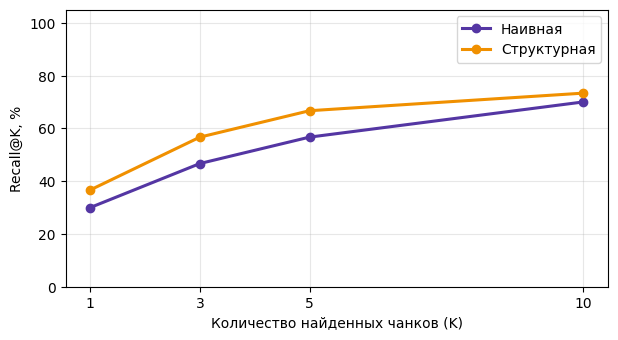

In [35]:
fig, ax = plt.subplots(figsize=(7, 3.6))

for (name, curve), color in zip(curves.items(), [COLORS["violet"], COLORS["amber"]]):
    ax.plot(list(curve), [v * 100 for v in curve.values()],
            marker="o", lw=2.2, color=color, label=name)

ax.set_xlabel("Количество найденных чанков (K)")
ax.set_ylabel("Recall@K, %")
ax.set_xticks([1, 3, 5, 10])
ax.set_ylim(0, 105)
ax.legend()
ax.grid(alpha=0.3)
fig.savefig("img/recall.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод по сравнению методов нарезки:**  
  
На корпусе из 8 PDF-документов были протестированы два способа нарезки текста:   
наивный (по 400 символов) и структурный (с учётом границ предложений).  
Качество поиска оценивалось с помощью Recall@K на наборе из 30 вопросов.  
   
Структурная нарезка показала лучшие результаты при всех значениях K.   
Поэтому, для дальнейшей реализации RAG-системы структурная нарезка выглядит более предпочтительной.   

Для дальнейших экспериментов я выбрала K = 5.  
При структурной нарезке Recall@5 составил 66,7%, а Recall@10  73,3%.   
Увеличение числа найденных чанков с 5 до 10 дало прирост всего 6,6%,  
но увеличило объём передаваемого модели контекста.  
Поэтому K= 5 выбрала как компромисс между качеством поиска и стоимостью генерации.

### MILVUS:

In [36]:
MILVUS_URI = os.getenv("MILVUS_URI", "http://localhost:19530")
client = MilvusClient( uri=MILVUS_URI, token=os.getenv("MILVUS_TOKEN", ""))

print("Версия Milvus:", client.get_server_version())
print("Коллекции:", client.list_collections())

Версия Milvus: 2.6.24
Коллекции: []


In [37]:
def index_to_milvus(name, chunks, vectors):
    if client.has_collection(name):
        raise ValueError(f"Коллекция {name} уже существует")
    client.create_collection(name, dimension=vectors.shape[1], metric_type="COSINE")
    rows = [{"id": i, "vector": v.tolist(), **c} for i, (c, v) in enumerate(zip(chunks, vectors))]
    for i in range(0, len(rows), 1000):
        client.insert(name, rows[i:i+1000])

    client.flush(name)
    return client.get_collection_stats(name)

In [38]:
index_to_milvus("char_chunks", char_chunks, char_vecs)

{'row_count': 1608}

In [39]:
index_to_milvus("structured_chunks", structured_chunks, structured_vecs)

{'row_count': 1940}

In [40]:
def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search( name, data=[vector], limit=k, filter=flt, output_fields=["page", "page_number", "section", "url", "text"])[0]
    return [ {**h["entity"], "id": h["id"], "score": round(h["distance"], 4)}
        for h in hits ]

In [41]:
pd.DataFrame( search_milvus("structured_chunks", tasks[0]["question"], 3))[["score", "page", "page_number", "text"]]

,score,page,page_number,text
0,0.7384,youtube-multitask.pdf,9,Deep neural networks for YouTube Recommendatio...
1,0.7131,45530.pdf,1,Deep Neural Networks for Y ouTube Recommendati...
2,0.6983,5716.pdf,9,Deep Neural Networks for YouTube Recommendatio...


In [42]:
from_numpy = [[i for i, _ in search_numpy(q, structured_vecs, 5)] for q in q_vecs]

from_milvus = [[h["id"] for h in hits]
    for hits in client.search( "structured_chunks", data=q_vecs.tolist(), limit=5)]

overlap = np.mean([ len(set(a) & set(b)) / 5
                for a, b in zip(from_numpy, from_milvus)])

print("Совпадение результатов:", round(overlap * 100, 1), "%")

Совпадение результатов: 94.7 %


**Фильтрация по PDF:**

In [43]:
pd.DataFrame( search_milvus( "structured_chunks", tasks[0]["question"], 3, 'page == "45530.pdf"'))[["score", "page", "page_number", "text"]]

,score,page,page_number,text
0,0.7131,45530.pdf,1,Deep Neural Networks for Y ouTube Recommendati...
1,0.6721,45530.pdf,7,CONCLUSIONS We have described our deep neural ...
2,0.6504,45530.pdf,1,YouTube recommendations are responsible for he...


### Поиск по словам:

In [45]:
def tokens(text):
    return re.findall(r"\w+", text.lower())


def build_keyword_index(texts):
    docs = [set(tokens(text)) for text in texts]
    df = {}

    for d in docs:
        for w in d:
            df[w] = df.get(w, 0) + 1

    return docs, {w: np.log(len(docs) / n) for w, n in df.items()}


def keyword_search(query, docs, idf, k=20):
    q = set(tokens(query))
    scores = np.array([sum(idf.get(w, 0.0) for w in q & d) for d in docs ])
    return [int(i) for i in np.argsort(-scores)[:k]]

In [46]:
def rrf(rankings, k=5, K=60):
    scores = {}

    for ranking in rankings:
        for rank, idx in enumerate(ranking):
            scores[idx] = scores.get(idx, 0.0) + 1 / (K + rank + 1)

    return sorted(scores, key=scores.get, reverse=True)[:k]

### Сравнение качества трёх способов поиска:
1) Векторный  (поиск по эмбеддингам)
2) По словам  (поиск по совпадению слов с учётом IDF)
3) Гибридный RRF  (объединение результатов первых двух методов)

In [47]:
def recall_of(rankings, chunks, k=5):
    return float(np.mean([ any(is_gold(chunks[i], t) for i in r[:k])
                        for r, t in zip(rankings, tasks) ]))

rows = []

for cut, chunks, vectors in [("Наивная", char_chunks, char_vecs), ("Структурная", structured_chunks, structured_vecs)]:
    docs, idf = build_keyword_index([c["text"] for c in chunks])

    by_vector = [ [i for i, _ in search_numpy(q, vectors, 20)]
                    for q in q_vecs]

    by_words = [ keyword_search(t["question"], docs, idf, 20) for t in tasks]

    by_hybrid = [ rrf([v, w], 20)
                for v, w in zip(by_vector, by_words) ]

    for name, rankings in [ ("Векторный", by_vector), ("По словам", by_words),("Гибрид RRF", by_hybrid)]:
        rows.append({ "Нарезка": cut, "Метод поиска": name, "Recall@1": recall_of(rankings, chunks, 1) * 100,
            "Recall@5": recall_of(rankings, chunks, 5) * 100 })

hybrid = pd.DataFrame(rows).round(1)
hybrid

,Нарезка,Метод поиска,Recall@1,Recall@5
0,Наивная,Векторный,30.0,56.7
1,Наивная,По словам,36.7,73.3
2,Наивная,Гибрид RRF,46.7,73.3
3,Структурная,Векторный,36.7,66.7
4,Структурная,По словам,50.0,80.0
5,Структурная,Гибрид RRF,36.7,73.3


**Вывод:**  
Наилучший результат показал поиск по словам на структурных чанках: Recall@1 составил 50%, Recall@5 80%.   
Гибридный поиск улучшил качество относительно векторного, однако оказался хуже поиска по словам.  
Вероятно, это связано с большим количеством слов в научных текстах, для которых точное совпадение особенно важно.   

## RAG: генерация ответов по документам

In [48]:
RAG_SYSTEM = ("Answer the question using only the numbered sources. Cite the source number like [2]. "
              "If the sources do not contain the answer, reply exactly NOT_FOUND. The last line must be FINAL: <short answer>.")
PLAIN_SYSTEM = "Answer the question. If you do not know, reply NOT_FOUND. The last line must be FINAL: <short answer>."

In [49]:
def rag_answer(question, model, k=5, name="structured_chunks"):
    hits = search_milvus(name, question, k)
    sources = "\n".join( f"[{i + 1}] ({h['page']}, стр. {h['page_number']}) {h['text']}"for i, h in enumerate(hits))
    before = ledger.mine
    msg = chat( [{"role": "system", "content": RAG_SYSTEM}, {"role": "user", "content": f"Sources:\n{sources}\n\nQuestion: {question}"}],
        model,tag="rag")

    return {"answer": msg.get("content") or "","hits": hits, "cost": ledger.mine - before }

**мини проверочка:**

In [50]:
out = rag_answer(tasks[0]["question"], MODELS["cheap"])

print("Вопрос:", tasks[0]["question"])
print("Ответ rag:", out["answer"])
print("Правильный ответ:", tasks[0]["answer"])
print("Стоимость:", round(out["cost"], 6))

Вопрос: How many neural networks make up the YouTube recommendation system described in the 2016 paper?
Ответ rag: The YouTube recommendation system described in the 2016 paper consists of two neural networks: one for candidate generation and another for candidate ranking [5]. 

FINAL: 2 neural networks.
Правильный ответ: two neural networks
Стоимость: 0.000106


In [51]:
def plain_answer(question, model):
    before = ledger.mine
    msg = chat( [{"role": "system", "content": PLAIN_SYSTEM},{"role": "user", "content": question}], model, tag="plain")
    return { "answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before}

def final_answer(text):
    m = re.findall(r"FINAL:\s*(.+)", text or "")
    return m[-1].strip() if m else (text or "").strip()


def is_correct(task, answer):
    return f" {norm(task['answer'])} " in f" {norm(final_answer(answer))} "

**Проверка работы функции, которая проверяет ответ:**

In [53]:
print("Ответ модели:", final_answer(out["answer"]))
print("Правильно:", is_correct(tasks[0], out["answer"]))

Ответ модели: 2 neural networks.
Правильно: True


In [98]:
def evaluate(fn, sample, config, model, workers=8):
    def one(task):
        try: out = fn(task["question"], model)
        except Exception as e:
            out = { "answer": f"ошибка: {e}", "hits": [], "cost": 0.0}

        return { "config": config, "model": model.split("/")[-1], "id": task["id"], "correct": is_correct(task, out["answer"]),
     "found": any(is_gold(h, task) for h in out["hits"]), "refused": "NOT_FOUND" in out["answer"],
     "cost": out["cost"], "answer": final_answer(out["answer"])[:60],
     "gold": task["answer"], "searches": out.get("searches", 0)}

    with ThreadPoolExecutor(workers) as pool:
        return pd.DataFrame(list(pool.map(one, sample)))

def report(results):
    g = results.groupby(["config", "model"], sort=False)
    table = g.agg(n=("correct", "size"), accuracy=("correct", "mean"), cost_per_task=("cost", "mean")).reset_index()
    table["cost_per_correct"] = table["cost_per_task"] / table["accuracy"].replace(0, float("nan"))
    return table.round(5)

In [55]:
sample = tasks

results = pd.concat([
    evaluate(plain_answer, sample, "Без RAG", MODELS["cheap"], workers=4),
    evaluate(plain_answer, sample, "Без RAG", MODELS["strong"], workers=4),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["cheap"], workers=4),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["mid"], workers=4),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["strong"], workers=4)
], ignore_index=True)

table = report(results)
table

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,Без RAG,gpt-4o-mini,30,0.10000,0.00003,0.00028
1,Без RAG,claude-sonnet-4.6,30,0.56667,0.00233,0.00412
2,"RAG, k=5",gpt-4o-mini,30,0.63333,0.00009,0.00015
3,"RAG, k=5",claude-haiku-4.5,30,0.66667,0.00109,0.00163
4,"RAG, k=5",claude-sonnet-4.6,30,0.66667,0.00302,0.00453


In [56]:
errors = results[results["answer"].str.startswith("ошибка:")]

print("Всего ответов:", len(results))
print("Ошибок API:", len(errors))
results.to_csv("data/rag_results.csv", index=False)

Всего ответов: 150
Ошибок API: 0


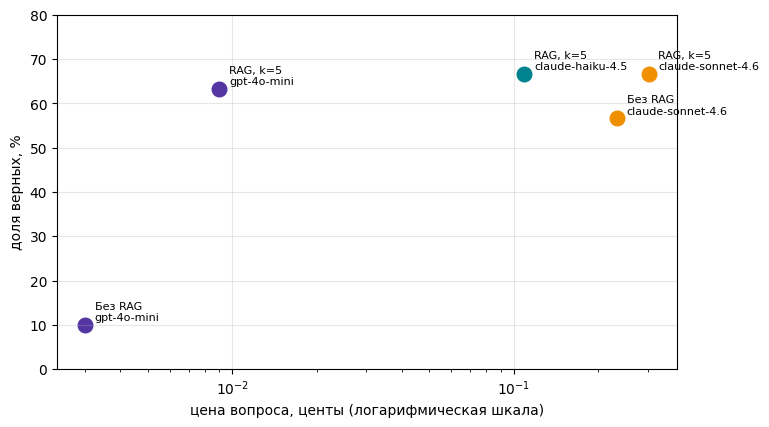

In [60]:
def money_chart(table, path, baseline=None):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    if baseline:
        ax.axhline(baseline[1] * 100, color=COLORS["grey"], ls="--", lw=1.2)
        ax.annotate(baseline[0], (0.01, baseline[1] * 100 + 1.5), xycoords=("axes fraction", "data"), fontsize=8, color=COLORS["grey"])
    for _, r in table.iterrows():
        color = COLORS["amber"] if "sonnet" in r["model"] else COLORS["teal"] if "haiku" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100), fontsize=8, xytext=(7, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %"); ax.grid(alpha=0.3)
    ax.set_ylim(0, 80)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig
    
_ = money_chart(table, "img/money_rag.png")

**Вывод:**   
В нашем эксперименте доступ к релевантным документам оказался важнее, чем использование более дорогой модели.

In [61]:
refusals = [rag_answer(t["question"], MODELS["cheap"])  for t in unanswerable]

refusal_table = pd.DataFrame({ "Вопрос": [t["question"] for t in unanswerable],
    "Ответ": [final_answer(r["answer"]) for r in refusals], "Отказ": ["NOT_FOUND" in r["answer"] for r in refusals]})

print("Корректных отказов:", refusal_table["Отказ"].sum(), "из 10")
refusal_table

Корректных отказов: 10 из 10


,Вопрос,Ответ,Отказ
0,Which exact ranking model architecture was dep...,NOT_FOUND,True
1,How many recommendation impressions did YouTub...,NOT_FOUND,True
2,What was the precise click-through rate for Yo...,NOT_FOUND,True
3,Which videos did a specific private YouTube ac...,NOT_FOUND.,True
4,What is the exact current number of parameters...,NOT_FOUND,True
5,What percentage of YouTube watch time came fro...,NOT_FOUND,True
6,How many videos were recommended to a particul...,NOT_FOUND,True
7,What are the names of every current experiment...,NOT_FOUND,True
8,What was YouTube's advertising revenue attribu...,NOT_FOUND.,True
9,What was the exact number of harmful recommend...,NOT_FOUND,True


**Вывод:**   
При проверке на 10 вопросах, ответы на которые отсутствуют в корпусе, RAG-система правильно отказалась отвечать во всех случаях.   

### Разбор провалов

In [62]:
def diagnose(results):
    wrong = results[~results["correct"] & results["config"].str.startswith("RAG")]
    return wrong.groupby("model").agg(не_нашли=("found", lambda s: int((~s).sum())), нашли_но_ответ_неверный=("found", "sum"))

diagnose(results)

,не_нашли,нашли_но_ответ_неверный
model,,
claude-haiku-4.5,7,3
claude-sonnet-4.6,9,1
gpt-4o-mini,8,3


In [63]:
wrong = results[ (~results["correct"]) & (results["config"] == "RAG, k=5") & (results["model"] == "gpt-4o-mini")]
examples = pd.concat([ wrong[~wrong["found"]].head(1), wrong[wrong["found"]].head(1)])
examples = examples.merge( pd.DataFrame(tasks)[["id", "question"]], on="id")

examples[["id", "question", "gold", "answer", "found"]]

,id,question,gold,answer,found
0,q004,What evaluation method does the 2016 YouTube p...,A/B testing,NOT_FOUND,False
1,q013,What happens to the final variance when the fr...,final variance is higher,Higher learning rate increases final variance.,True


In [67]:
task = next(t for t in tasks if t["id"] == "q004")
hits = search_milvus("structured_chunks", task["question"], 5)

pd.DataFrame([
    { "PDF": h["page"], "Страница": h["page_number"], "Правильный чанк": is_gold(h, task), "Текст": h["text"][:250] }
    for h in hits])

,PDF,Страница,Правильный чанк,Текст
0,youtube-multitask.pdf,6,False,We report results on both the engagement metri...
1,1812.02353v3.pdf,7,False,We evaluate these methods on a production RNN ...
2,youtube-multitask.pdf,6,False,We examine multiple engagement metrics such as...
3,45530.pdf,2,False,Although explicit feedback mechanisms exist on...
4,youtube-multitask.pdf,6,False,"5 EXPERIMENT RESULTS In this section, we descr..."


**Пример ошибки поиска(q004)**
Анализ пяти найденных фрагментов показал, что ни один из них не содержал необходимой информации.  
При этом среди результатов была нужная статья и даже нужная страница, но другой участок текста.  


In [68]:
for k in (5, 10, 20):
    hits_k = search_milvus("structured_chunks", task["question"], k)
    found = any(is_gold(h, task) for h in hits_k)

    print(f"K={k}: правильный чанк найден  {found}")

K=5: правильный чанк найден  False
K=10: правильный чанк найден  False
K=20: правильный чанк найден  True


**Вывод по ошибке в поиске:**   
при K=5 и K=10 правильный фрагмент не находился, однако при K=20 он появился в результатах поиска.  
Таким образом, увеличение глубины поиска позволило устранить ошибку для данного вопроса, но использование большего количества чанков повышает стоимость последующей генерации.  

In [64]:
found_wrong = wrong[wrong["found"]]

found_wrong[["id", "gold", "answer"]]

,id,gold,answer
72,q013,final variance is higher,Higher learning rate increases final variance.
81,q022,Recurrent Neural Network,RNN.
82,q023,Interpretability,Difficulty in providing explainable predictions.


**Вывод: все три ответа GPT-4o-mini на самом деле правильные по смыслу.**

In [66]:
generation_errors = results[(~results["correct"]) & (results["found"]) & (results["config"].str.startswith("RAG"))]
generation_errors[["model", "id", "gold", "answer"]]

,model,id,gold,answer
72,gpt-4o-mini,q013,final variance is higher,Higher learning rate increases final variance.
81,gpt-4o-mini,q022,Recurrent Neural Network,RNN.
82,gpt-4o-mini,q023,Interpretability,Difficulty in providing explainable predictions.
102,claude-haiku-4.5,q013,final variance is higher,A higher learning rate results in higher final...
106,claude-haiku-4.5,q017,micro-divergence and full divergence,The two types of loss divergence are micro-div...
109,claude-haiku-4.5,q020,Hybrid model,A hybrid recommender system integrates two or ...
132,claude-sonnet-4.6,q013,final variance is higher,The final variance increases when a higher lea...


**Вывод по анализу ошибок генерации**

При разборе случаев, когда правильный фрагмент был найден, но ответ модели оценивался как неверный, оказалось, что ответы были корректными по смыслу. Модели использовали другие формулировки, сокращения или меняли порядок слов, из-за чего функция is_correct() не засчитывала их как правильные.  
Рассчитанная точность моделей может быть занижена.  
Для более объективной оценки качества ответов необходимо дополнительно учитывать их смысловое соответствие эталону.  

Для Claude Haiku 4.5, которая показала лучшее соотношение точности и стоимости, также встретились оба типа проблем. Например, в вопросе q004 нужный фрагмент не попал в результаты поиска, а в вопросе q020 ответ не был засчитан из-за отличия формулировки от эталона.  

### Поиск как инструмент агента

In [93]:
class KBArgs(BaseModel):
    query: str = Field( description="Search query about recommendation systems" )
    page: str = Field( default="", description="Optional exact PDF filename, e.g. 45530.pdf")


def knowledge_base(query: str, page: str = "", return_hits: bool = False):
    flt = f'page == "{page}"' if page else ""
    hits = search_milvus( "structured_chunks", query, 5, flt)
    if not hits:
        result = "nothing found"
    else:
        result = "\n".join( f"[{h['page']} / стр. {h['page_number']}] {h['text']}" for h in hits)

    if return_hits:
        return result, hits

    return result

In [70]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}


In [94]:
register(knowledge_base,KBArgs, "Searches PDF documents about recommendation systems. "
         "Returns relevant fragments with filenames and page numbers.")

print("Зарегистрированные инструменты:", list(TOOLS))

Зарегистрированные инструменты: ['knowledge_base']


In [72]:
query = tasks[0]["question"]

tests = [("Обычный поиск", {"query": query}),("Фильтр по PDF", {"query": query, "page": "45530.pdf"}),
         ("Нет документа", {"query": query, "page": "missing.pdf"})]

for name, params in tests:
    args = KBArgs.model_validate(params)
    result = knowledge_base(**args.model_dump())
    print(name)
    print(result[:250])
    print()

Обычный поиск
[youtube-multitask.pdf / стр. 9] Deep neural networks for YouTube Recommendations. In Proceedings of the 10th ACM conference on recommender systems. ACM, 191–198. [11] James Davidson, Benjamin Liebald, Junning Liu, Palash Nandy, Taylor Van Vleet, Ull

Фильтр по PDF
[45530.pdf / стр. 1] Deep Neural Networks for Y ouTube Recommendations Paul Covington, Jay Adams, Emre Sargin Google Mountain View, CA {pcovington, jka, msargin}@google.com ABSTRACT YouTube represents one of the largest scale and most sophisticated i

Нет документа
nothing found



**Агент с инструментом knowledge_base:**

In [96]:
def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json( call["function"]["arguments"]).model_dump()

        if name == "knowledge_base":
            result, hits = spec["fn"]( **args, return_hits=True)
        else:
            result = spec["fn"](**args)
            hits = []

    except Exception as e:
        result = f"ошибка инструмента {name}: {e}"
        hits = []

    tool_message = { "role": "tool", "tool_call_id": call["id"], "content": str(result)[:3000]}

    return tool_message, hits


AGENT_SYSTEM = ( "You answer questions about recommendation systems based on scientific PDF documents. "
    "You have access to the knowledge_base tool. Decide when you need to search for information. "
    "Use retrieved evidence for factual claims. Do not invent facts or sources. "
    "If the available information does not contain the answer, reply NOT_FOUND. "
    "The last line must be FINAL: <short answer>.")


def agent(question, model, max_steps=6):
    messages, seen, before = [ {"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question} ], set(), ledger.mine
    schemas = [t["schema"] for t in TOOLS.values()]
    all_hits = []
    searches = 0

    for step in range(max_steps):
        msg = chat(messages, model, tools=schemas, tag="agent")
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        keys = { (c["function"]["name"], c["function"]["arguments"]) for c in calls}
        if not calls or keys & seen or step == max_steps - 1:
            break
        seen |= keys

        for call in calls:
            tool_message, hits = run_tool(call)
            messages.append(tool_message)
            all_hits.extend(hits)
            searches += 1

    if calls:
        messages += [ { "role": "tool", "tool_call_id": c["id"], "content": "call rejected: answer from what you already have"} for c in calls]
        msg = chat(messages, model, tag="agent")

    return { "answer": msg.get("content") or "", "hits": all_hits, "cost": ledger.mine - before, "searches": searches}

In [97]:
test_agent = agent( tasks[0]["question"], MODELS["cheap"])

print("Вопрос:", tasks[0]["question"])
print("Ответ:", final_answer(test_agent["answer"]))
print("\nВызовов инструмента:", test_agent["searches"])
print("Найдено чанков:", len(test_agent["hits"]))
print("Стоимость:", round(test_agent["cost"], 7), "$")
print("Правильность ответа:", is_correct(tasks[0], test_agent["answer"]))

Вопрос: How many neural networks make up the YouTube recommendation system described in the 2016 paper?
Ответ: 2 neural networks.

Вызовов инструмента: 3
Найдено чанков: 15
Стоимость: 0.0005343 $
Правильность ответа: True


In [99]:
agent_path = DATA / "agent_results.csv"

if agent_path.exists():
    agent_results = pd.read_csv(agent_path)
    print("Результаты загружены из файла.")

else:
    agent_results = evaluate( agent, tasks, "Агент + knowledge_base", MODELS["cheap"], workers=2)
    errors = agent_results["answer"].str.startswith("ошибка:").sum()
    if errors == 0:
        agent_results.to_csv(agent_path, index=False)
        print("Результаты сохранены в:", agent_path)
    else:
        print("Обнаружены ошибки:", errors)
        print("Результаты пока не сохраняем.")

print("Всего ответов:", len(agent_results))
print("Правильных ответов:", agent_results["correct"].sum())
print("Точность:", round(agent_results["correct"].mean() * 100, 1), "%")
print("Всего вызовов инструмента:", agent_results["searches"].sum())
print( "Вопросов с использованием инструмента:", (agent_results["searches"] > 0).sum())
print("Общая стоимость:", round(agent_results["cost"].sum(), 6), "$")
agent_results[ ["id", "correct", "found", "refused", "searches", "cost"]]

Результаты сохранены в: data\agent_results.csv
Всего ответов: 30
Правильных ответов: 19
Точность: 63.3 %
Всего вызовов инструмента: 39
Вопросов с использованием инструмента: 30
Общая стоимость: 0.006833 $


,id,correct,found,refused,searches,cost
0,q001,True,False,False,3,0.000503
1,q002,True,True,False,1,0.000134
2,q003,True,False,False,1,0.000163
3,q004,False,False,False,1,0.000174
4,q005,True,True,False,1,0.000138
5,q006,False,False,False,2,0.000326
6,q007,True,True,False,1,0.000161
7,q008,False,False,False,1,0.000153
8,q009,False,False,False,1,0.000146
9,q010,False,False,True,5,0.001154


In [100]:
base_results = results[ results["config"] != "Агент + knowledge_base"].copy()
all_results = pd.concat( [base_results, agent_results], ignore_index=True)
table_full = report(all_results)
all_results.to_csv( DATA / "rag_results_full.csv", index=False)
table_full.to_csv( DATA / "rag_report_full.csv", index=False)
print("Всего ответов:", len(all_results))
print("Количество конфигураций:", len(table_full))
table_full

Всего ответов: 180
Количество конфигураций: 6


,config,model,n,accuracy,cost_per_task,cost_per_correct
0,Без RAG,gpt-4o-mini,30,0.10000,0.00003,0.00028
1,Без RAG,claude-sonnet-4.6,30,0.56667,0.00233,0.00412
2,"RAG, k=5",gpt-4o-mini,30,0.63333,0.00009,0.00015
3,"RAG, k=5",claude-haiku-4.5,30,0.66667,0.00109,0.00163
4,"RAG, k=5",claude-sonnet-4.6,30,0.66667,0.00302,0.00453
5,Агент + knowledge_base,gpt-4o-mini,30,0.63333,0.00023,0.00036


**Итоговое сравнение качества и стоимости шести конфигураций:**

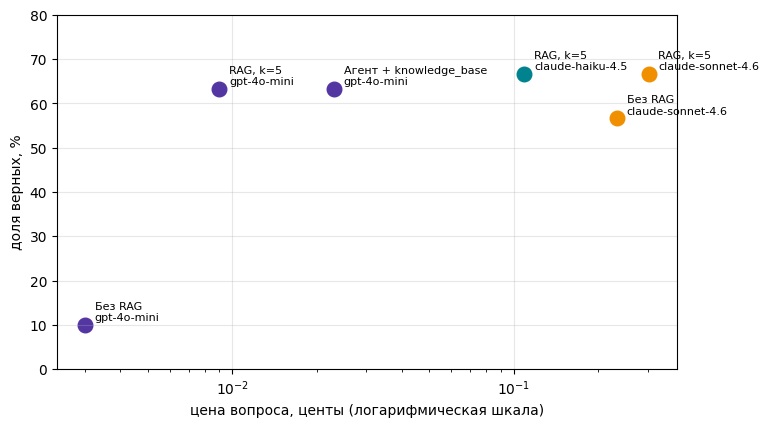

In [101]:
fig = money_chart( table_full, "img/money_rag_full.png")
plt.show()

**Анализ ложных отказов на вопросах с известными ответами:**

In [102]:
refusal_results = all_results.copy()
refusal_results["false_refusal"] = ( refusal_results["answer"] .fillna("") .astype(str).str.strip().eq("NOT_FOUND"))
false_refusals = ( refusal_results .groupby(["config", "model"], sort=False).agg( questions=("id", "size"), false_refusals=("false_refusal", "sum")).reset_index())
false_refusals["refusal_rate"] = (false_refusals["false_refusals"]/ false_refusals["questions"] * 100).round(1)
false_refusals.to_csv( DATA / "false_refusals.csv", index=False)
false_refusals

,config,model,questions,false_refusals,refusal_rate
0,Без RAG,gpt-4o-mini,30,5,16.7
1,Без RAG,claude-sonnet-4.6,30,2,6.7
2,"RAG, k=5",gpt-4o-mini,30,4,13.3
3,"RAG, k=5",claude-haiku-4.5,30,1,3.3
4,"RAG, k=5",claude-sonnet-4.6,30,3,10.0
5,Агент + knowledge_base,gpt-4o-mini,30,1,3.3


**Проверка отказов агента на вопросах без ответа:**

In [106]:
agent_refusals_path = DATA / "agent_unanswerable.csv"

if agent_refusals_path.exists():
    agent_refusals = pd.read_csv(agent_refusals_path)
    print("Результаты загружены из файла")

else:
    rows = []
    for i, task in enumerate(unanswerable, 1):
        try:
            out = agent(task["question"], MODELS["cheap"])
            answer = final_answer(out["answer"])
            rows.append({  "question": task["question"],  "answer": answer,  "searches": out["searches"], "cost": out["cost"], "error": False})
        except Exception as e:
            rows.append({ "question": task["question"], "answer": f"ошибка: {e}", "searches": 0, "cost": 0.0, "error": True})

        print(f"Обработано вопросов: {i}/10")
    agent_refusals = pd.DataFrame(rows)

agent_refusals["refused"] = ( agent_refusals["answer"].fillna("") .astype(str).str.strip().str.fullmatch(r"(?i)NOT_FOUND[.!]?").fillna(False))
has_errors = ( agent_refusals["error"].astype(str).str.lower().eq("true").any() if "error" in agent_refusals.columns else False)

if not has_errors:
    agent_refusals.to_csv(agent_refusals_path, index=False)
    print("Результаты сохранены")
else:
    print("есть ошибки API")

print("Корректных отказов:", agent_refusals["refused"].sum(), "из 10")
print("Общая стоимость:", round(agent_refusals["cost"].sum(), 6), "$")
agent_refusals[["question", "answer", "refused", "searches", "cost"]]

Результаты загружены из файла
Результаты сохранены
Корректных отказов: 10 из 10
Общая стоимость: 0.002326 $


,question,answer,refused,searches,cost
0,Which exact ranking model architecture was dep...,NOT_FOUND.,True,1,0.000244
1,How many recommendation impressions did YouTub...,NOT_FOUND,True,1,0.000156
2,What was the precise click-through rate for Yo...,NOT_FOUND,True,1,0.000129
3,Which videos did a specific private YouTube ac...,NOT_FOUND,True,0,0.000031
4,What is the exact current number of parameters...,NOT_FOUND,True,1,0.000150
5,What percentage of YouTube watch time came fro...,NOT_FOUND,True,1,0.000171
6,How many videos were recommended to a particul...,NOT_FOUND,True,1,0.000131
7,What are the names of every current experiment...,NOT_FOUND,True,1,0.000128
8,What was YouTube's advertising revenue attribu...,NOT_FOUND,True,1,0.000149
9,What was the exact number of harmful recommend...,NOT_FOUND.,True,5,0.001036


**Итоговое сравнение отказов RAG и агента:**

In [107]:
def count_refusals(answers):
    return int( answers.fillna("").astype(str).str.strip().str.fullmatch(r"(?i)NOT_FOUND[.!]?").fillna(False).sum())

rag_answers = all_results[ (all_results["config"] == "RAG, k=5") & (all_results["model"] == "gpt-4o-mini")]
agent_answers = all_results[all_results["config"] == "Агент + knowledge_base"]
refusal_summary = pd.DataFrame([{ "Система": "RAG всегда", 
      "Корректных отказов (из 10)": count_refusals(refusal_table["Ответ"]),
        "Ложных отказов (из 30)": count_refusals(rag_answers["answer"])},
    { "Система": "Агент + knowledge_base","Корректных отказов (из 10)": count_refusals(agent_refusals["answer"]),"Ложных отказов (из 30)": count_refusals(agent_answers["answer"])}])

refusal_summary.to_csv( DATA / "refusal_summary.csv", index=False)
refusal_summary

,Система,Корректных отказов (из 10),Ложных отказов (из 30)
0,RAG всегда,10,4
1,Агент + knowledge_base,10,1


**Вывод:**  
Обе системы правильно отказались отвечать на все 10 вопросов,   
для которых в документах не было ответа.   
При этом агент с knowledge_base допустил только один ложный отказ на 30 вопросах,  
а обычный RAG  четыре.  
Получается, агент реже отказывался отвечать при наличии информации,  
хотя общая точность у двух подходов оказалась одинаковой,   
а стоимость работы агента выше

## Память агента

In [73]:
FACTS_SYSTEM = (
    "Ты ведёшь память ассистента о пользователе. Верни один JSON-объект вида {\"facts\": [\"...\"]}: полный обновлённый список "
    "коротких фактов о пользователе. Добавь новые устойчивые факты: имя, город, работа, интересы, пожелания к ответам. "
    "Если новый факт отменяет старый, замени старый. Разовые вопросы и мелочи не записывай.")

ASSISTANT_SYSTEM = (
    "Ты помощник, который отвечает на вопросы о рекомендательных системах по базе научных документов. Отвечай на языке пользователя, "
    "опирайся на источники и на то, что знаешь о пользователе. Источники могут быть не по теме: используй только релевантные. "
    "Если в источниках ответа нет, так и скажи.")

JOURNAL = Path("episodes.jsonl")
FACTS_FILE = Path("facts.json")

class Facts(BaseModel):
    facts: list[str] = Field(description="короткие факты о пользователе")

In [74]:
def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    cleaned = re.sub(r'(\\["\\/bfnrtu])|\\', lambda e: e.group(1) or "\\\\", m.group(0) if m else "{}")
    return json.loads(cleaned, strict=False)

def known_facts():
    return json.loads(FACTS_FILE.read_text(encoding="utf-8")) if FACTS_FILE.exists() else []

def store_facts(facts):
    if client.has_collection("facts"):
        client.drop_collection("facts")

    if facts:
        chunks = [ { "page": "memory", "page_number": 0,  "section": "",  "url": "", "text": f } for f in facts ]
        index_to_milvus("facts", chunks, embed_cached(facts))

    FACTS_FILE.write_text( json.dumps(facts, ensure_ascii=False, indent=1), encoding="utf-8")
    
def remember_episode(session, role, text):
    with JOURNAL.open("a", encoding="utf-8") as f:
        f.write(json.dumps({"session": session, "time": time.strftime("%Y-%m-%d %H:%M:%S"), "role": role, "text": text}, ensure_ascii=False) + "\n")


In [75]:
def extract_facts(dialog, known):
    prompt = f"Известные факты: {json.dumps(known, ensure_ascii=False)}\n\nДиалог:\n{dialog}"
    msg = chat([{"role": "system", "content": FACTS_SYSTEM}, {"role": "user", "content": prompt}], MODELS['cheap'], tag="memory")
    return Facts.model_validate(json_from(msg["content"])).facts
    

In [76]:
def recall_facts(question, k=3):
    if not client.has_collection("facts"):
        return []
    return [h["text"] for h in search_milvus("facts", question, k)]


In [78]:
def search_with_memory(user_text, facts, k=5):
    plain = search_milvus("structured_chunks", user_text, k)
    personal = search_milvus( "structured_chunks", user_text + " " + " ".join(facts), k  ) if facts else []
    by_id = {h["id"]: h for h in plain + personal}
    return [ by_id[i] for i in rrf( [[h["id"] for h in plain], [h["id"] for h in personal]], k ) ]


def talk(session, history, user_text, mode="память"):
    remember_episode(session, "user", user_text)
    facts = recall_facts(user_text) if mode == "память" else []
    hits = search_with_memory(user_text, facts) if "?" in user_text else []
    sources = "\n".join( f"[{i + 1}] ({h['page']}, стр. {h['page_number']}) {h['text']}" for i, h in enumerate(hits) ) or "нет"
    system = ASSISTANT_SYSTEM + ( "\nЧто известно о пользователе: " + "; ".join(facts) if facts else "")
    window = history[-4:] if mode == "память" else history
    msg = chat( [{"role": "system", "content": system}] + window + [{"role": "user", "content": f"Источники:\n{sources}\n\n{user_text}"}],
        MODELS["cheap"], tag=f"dialog: {mode}")
    answer = msg.get("content") or ""
    history += [{ "role": "user", "content": user_text if mode == "память"  else f"Источники:\n{sources}\n\n{user_text}" },
        {"role": "assistant", "content": answer} ]
    remember_episode(session, "assistant", answer)
    return answer


def end_session(history):
    dialog = "\n".join( f"{m['role']}: {m['content'][:400]}" for m in history )
    store_facts(extract_facts(dialog, known_facts()))
    return known_facts()

In [79]:
first = []
print(talk( "s1", first,"Привет! Меня зовут Даша, я живу в Москве. "
            "Интересуюсь рекомендательными системами YouTube. Отвечай кратко."))

print(talk("s1", first, "Как устроены этапы рекомендации видео на YouTube?"))
print("\nФакты после первой сессии:")
print(end_session(first))

Привет, Даша! Рекомендательные системы YouTube используют алгоритмы, основанные на машинном обучении, чтобы предлагать пользователям видео, которые могут их заинтересовать. Они анализируют поведение пользователей, такие как просмотры, лайки и комментарии, а также учитывают популярность видео и взаимодействия других пользователей. Это помогает создавать персонализированные рекомендации. Если у тебя есть конкретные вопросы, спрашивай!
Этапы рекомендации видео на YouTube можно описать следующим образом:

1. **Сбор данных**: Алгоритм анализирует поведение пользователей, включая просмотры, лайки, комментарии и время просмотра.

2. **Оценка вовлеченности**: Алгоритм предсказывает, насколько вероятно, что видео заинтересует пользователя, учитывая его предпочтения и взаимодействия с контентом.

3. **Соблюдение правил**: Видео также оцениваются на соответствие Сообществу YouTube, чтобы избежать рекомендаций контента, нарушающего правила платформы (источник [1]).

4. **Персонализация**: На основ

In [80]:
second = []
print("История новой сессии:", len(second))
print(talk( "s2", second, "Привет! Напомни, как меня зовут, где я живу и какой формат ответов предпочитаю?"))

print(talk( "s2", second, "Я переехала в Казань. Теперь предпочитаю подробные ответы вместо коротких."))
print("\nФакты после второй сессии:")
print(end_session(second))

История новой сессии: 0
Привет, Даша! Ты интересуешься рекомендательными системами, особенно на YouTube, и предпочитаешь краткие ответы.
Поняла, Даша! Теперь ты в Казани и предпочитаешь подробные ответы. Если у тебя есть вопросы о рекомендательных системах, не стесняйся спрашивать!

Факты после второй сессии:
['Имя: Даша', 'Город: Казань', 'Интересы: рекомендательные системы YouTube', 'Пожелания к ответам: отвечать подробно']


**Вывод:**  
Агент сохранил информацию о пользователе и смог вспомнить её даже при пустой истории нового диалога.  
При изменении города и предпочтений к ответам старые факты заменились новыми.   
Но агент вспомнил не всю информацию, так как поиск возвращал только часть сохранённых фактов.   

#### Тесты без модели

**работа с пустой памятью**

In [81]:
TEST_DIR = Path("tests/memory")
TEST_DIR.mkdir(parents=True, exist_ok=True)
empty_facts_file = TEST_DIR / "empty_facts.json"
empty_facts_file.write_text("[]", encoding="utf-8")
original_facts_file = FACTS_FILE
try:
    FACTS_FILE = empty_facts_file
    print("Факты:", known_facts())
    print("Тест пройден:", known_facts() == [])

finally:
    FACTS_FILE = original_facts_file

Факты: []
Тест пройден: True


**Поиск сохранённого факта в Milvus**

In [108]:
stored_facts = client.query( collection_name="facts", filter='page == "memory"', output_fields=["text", "vector"], limit=100)
city_fact = next( (f for f in stored_facts if "Казань" in f["text"]), None)
assert city_fact is not None, "Факт о городе не найден в памяти"

query_vector = list(city_fact["vector"])
found_facts = client.search(collection_name="facts", data=[query_vector], limit=3, output_fields=["text"])[0]
found = any( "Казань" in item["entity"]["text"] for item in found_facts)
print("Сохранённый факт:", city_fact["text"])
print("Факт найден поиском:", found)
print("Тест пройден:", found)

Сохранённый факт: Город: Казань
Факт найден поиском: True
Тест пройден: True


**Проверка обновления и сохранения фактов**

In [82]:
facts = known_facts()
milvus_data = client.query( collection_name="facts", filter='page == "memory"', output_fields=["text"], limit=100)
milvus_facts = [item["text"] for item in milvus_data]
checks = { "Новый город сохранён": any("Казань" in f for f in facts), "Старый город удалён": not any("Москва" in f for f in facts),
    "Новые предпочтения сохранены": any("подробно" in f for f in facts), "Старые предпочтения удалены": not any("кратко" in f for f in facts), 
    "JSON и Milvus совпадают": sorted(facts) == sorted(milvus_facts)}

for name, result in checks.items():
    print(f"{name}: {result}")

print("\nВсе тесты пройдены:", all(checks.values()))

Новый город сохранён: True
Старый город удалён: True
Новые предпочтения сохранены: True
Старые предпочтения удалены: True
JSON и Milvus совпадают: True

Все тесты пройдены: True


**Проверка сохранения истории сессий**

In [83]:
episodes = [json.loads(line) for line in JOURNAL.read_text(encoding="utf-8").splitlines() if line.strip()]
sessions = {episode["session"] for episode in episodes}

print("Всего записей:", len(episodes))
print("Найденные сессии:", sorted(sessions))
print("Первая сессия сохранена:", "s1" in sessions)
print("Вторая сессия сохранена:", "s2" in sessions)

Всего записей: 8
Найденные сессии: ['s1', 's2']
Первая сессия сохранена: True
Вторая сессия сохранена: True


**Сравнение расхода токенов: полная история и память агента**

In [84]:
SCRIPT = [t["question"] for t in tasks[:10]]
print("Количество вопросов:", len(SCRIPT))

for i, question in enumerate(SCRIPT, 1):
    print(f"{i}. {question}")

Количество вопросов: 10
1. How many neural networks make up the YouTube recommendation system described in the 2016 paper?
2. Approximately how many candidate videos does the candidate generation network retrieve?
3. What does the YouTube ranking model aim to predict instead of click probability?
4. What evaluation method does the 2016 YouTube paper use for the final determination of model effectiveness?
5. What lookup method is used at serving time to generate hundreds of candidate video recommendations?
6. Which two categories of user behavior does the proposed multitask ranking system predict?
7. Which model architecture is extended by adding a shallow tower for selection bias?
8. What component corrects ranking selection bias in the proposed multitask system?
9. What are the two stages of the large-scale video recommendation system?
10. What neural network architecture does the sampling-bias-correction paper use for retrieval?


In [85]:
full_history = []
full_costs = []
original_journal = JOURNAL

try:
    JOURNAL = TEST_DIR / "benchmark_episodes.jsonl"
    for i, question in enumerate(SCRIPT, 1):
        before = ledger.mine
        answer = talk( "benchmark_full", full_history, question, mode="вся история")
        cost = ledger.mine - before
        full_costs.append(cost)
        print(f"Вопрос {i}: ${cost:.7f}")
finally:
    JOURNAL = original_journal

print("\nВсего вопросов:", len(full_costs))
print("Общая стоимость:", round(sum(full_costs), 6), "$")

Вопрос 1: $0.0001382
Вопрос 2: $0.0001838
Вопрос 3: $0.0001995
Вопрос 4: $0.0002333
Вопрос 5: $0.0002360
Вопрос 6: $0.0003096
Вопрос 7: $0.0003144
Вопрос 8: $0.0003695
Вопрос 9: $0.0004257
Вопрос 10: $0.0004749

Всего вопросов: 10
Общая стоимость: 0.002885 $


Теперь используем те же 10 вопросов, но в режиме где вместо полной истории передаются последние сообщения и найденные факты:

In [86]:
memory_history = []
memory_costs = []
original_journal = JOURNAL

try:
    JOURNAL = TEST_DIR / "benchmark_episodes.jsonl"

    for i, question in enumerate(SCRIPT, 1):
        before = ledger.mine
        answer = talk( "benchmark_memory", memory_history, question, mode="память")
        cost = ledger.mine - before
        memory_costs.append(cost)
        print(f"Вопрос {i}: ${cost:.7f}")

finally:
    JOURNAL = original_journal

print("\nВсего вопросов:", len(memory_costs))
print("Общая стоимость:", round(sum(memory_costs), 6), "$")

Вопрос 1: $0.0001720
Вопрос 2: $0.0001571
Вопрос 3: $0.0001850
Вопрос 4: $0.0001819
Вопрос 5: $0.0001586
Вопрос 6: $0.0001892
Вопрос 7: $0.0001561
Вопрос 8: $0.0001541
Вопрос 9: $0.0001549
Вопрос 10: $0.0001634

Всего вопросов: 10
Общая стоимость: 0.001672 $


In [87]:
full_total = sum(full_costs)
memory_total = sum(memory_costs)

print("Полная история:", round(full_total, 6), "$")
print("Память агента:", round(memory_total, 6), "$")

difference = (full_total - memory_total) / full_total * 100
print(f"Разница в стоимости: {difference:.1f}%")

Полная история: 0.002885 $
Память агента: 0.001672 $
Разница в стоимости: 42.0%


**Сравнение стоимости запросов:**

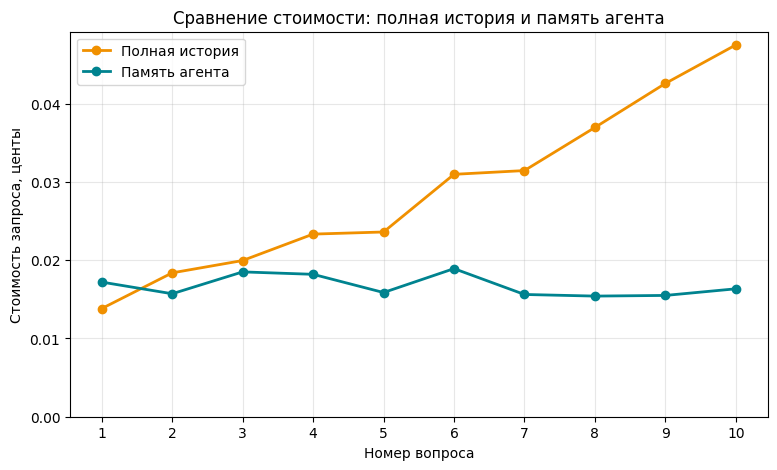

In [88]:
x = range(1, 11)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot( x, [c * 100 for c in full_costs], marker="o", linewidth=2, color=COLORS["amber"], label="Полная история")
ax.plot( x, [c * 100 for c in memory_costs], marker="o", linewidth=2, color=COLORS["teal"], label="Память агента")
ax.set_xlabel("Номер вопроса")
ax.set_ylabel("Стоимость запроса, центы")
ax.set_title("Сравнение стоимости: полная история и память агента")
ax.set_xticks(list(x))
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.3)

Path("img").mkdir(exist_ok=True)
fig.savefig("img/memory_cost.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:**  
В ходе эксперимента сравнила два способа работы с историей диалога.   
При передаче всей истории стоимость каждого следующего запроса увеличивалась, а при использовании памяти агента оставалась примерно на одном уровне. В результате второй вариант оказался на 42% дешевле.   
Получается хранение отдельных фактов и использование короткой истории может заметно снизить затраты при длительном общении с агентом.

**Токены:**

In [90]:
n = len(SCRIPT)

full_calls = [ c for c in ledger.calls if c["tag"] == "dialog: вся история"][-n:]
memory_calls = [ c for c in ledger.calls if c["tag"] == "dialog: память"][-n:]
assert len(full_calls) == n
assert len(memory_calls) == n

token_table = pd.DataFrame({"Вопрос": range(1, n + 1), "Полная история (вход)": [c["prompt"] for c in full_calls],
    "Память (вход)": [c["prompt"] for c in memory_calls],
    "Полная история (всего)": [ c["prompt"] + c["completion"] for c in full_calls ],
    "Память (всего)": [ c["prompt"] + c["completion"] for c in memory_calls]})

full_tokens = token_table["Полная история (всего)"].sum()
memory_tokens = token_table["Память (всего)"].sum()

print("Полная история:", full_tokens, "токенов")
print("Память агента:", memory_tokens, "токенов")

if full_tokens > 0:
    saving = (full_tokens - memory_tokens) / full_tokens * 100
    print(f"Экономия токенов: {saving:.1f}%")
else:
    print("API не вернул данные о токенах.")

token_table

Полная история: 27910 токенов
Память агента: 8349 токенов
Экономия токенов: 70.1%


,Вопрос,Полная история (вход),Память (вход),Полная история (всего),Память (всего)
0,1,585,619,669,749
1,2,1053,652,1096,749
2,3,1526,806,1605,911
3,4,2011,761,2089,872
4,5,2461,750,2495,825
5,6,2912,802,3004,915
6,7,3408,738,3448,812
7,8,3895,780,3953,840
8,9,4386,722,4479,798
9,10,4982,810,5072,878


**Сравнение общего количества токенов (входные + выходные):**

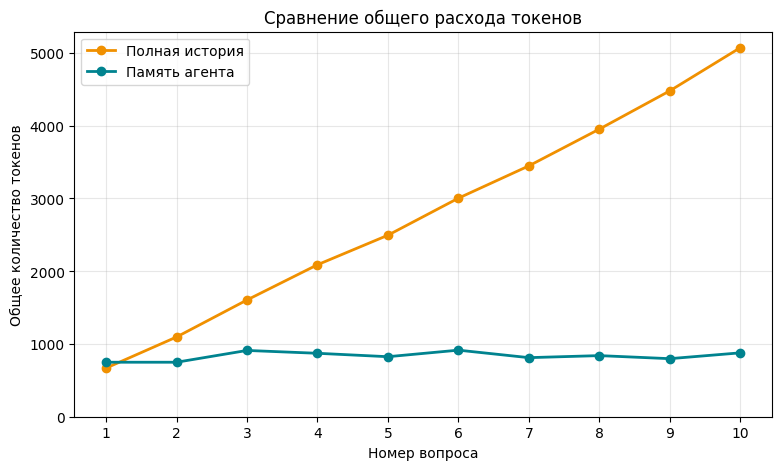

In [109]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot( token_table["Вопрос"], token_table["Полная история (всего)"], marker="o", linewidth=2, color=COLORS["amber"], label="Полная история")
ax.plot( token_table["Вопрос"], token_table["Память (всего)"], marker="o", linewidth=2, color=COLORS["teal"], label="Память агента")
ax.set_xlabel("Номер вопроса")
ax.set_ylabel("Общее количество токенов")
ax.set_title("Сравнение общего расхода токенов")
ax.set_xticks(range(1, 11))
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.3)

fig.savefig("img/memory_tokens.png", dpi=150, bbox_inches="tight")

plt.show()

**Итоговый вывод:**   
При использовании полной истории количество токенов увеличивалось с каждым новым вопросом, поскольку модели приходилось обрабатывать всё больше предыдущих сообщений.  
В режиме с памятью расход оставался примерно на одном уровне.   
За 10 вопросов удалось сократить количество токенов на **70,1%**, а стоимость запросов на **42%**.    
Следовательно, использование памяти и ограниченного окна истории позволяет заметно снизить затраты при длительном диалоге.

**Сравнение количества входных токенов:**

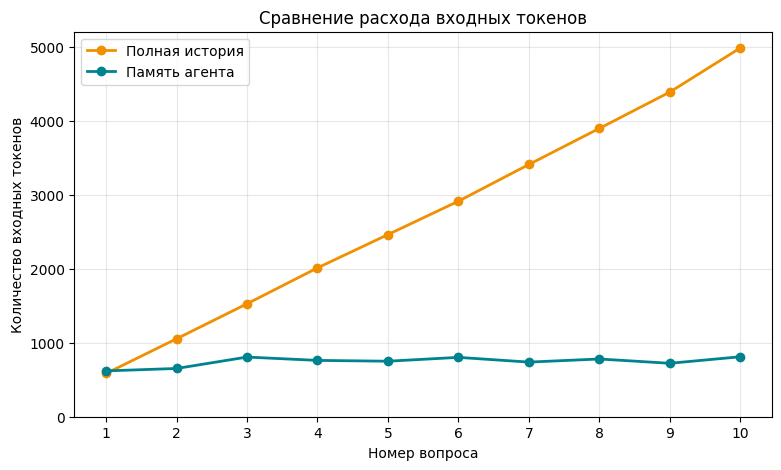

Полная история: 27219 входных токенов
Память агента: 7440 входных токенов
Экономия входных токенов: 72.7%

Стоимость полной истории: 0.002885 $
Стоимость памяти агента: 0.001672 $


In [110]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot( token_table["Вопрос"], token_table["Полная история (вход)"], marker="o", linewidth=2, color=COLORS["amber"], label="Полная история")
ax.plot( token_table["Вопрос"], token_table["Память (вход)"], marker="o", linewidth=2, color=COLORS["teal"], label="Память агента")
ax.set_xlabel("Номер вопроса")
ax.set_ylabel("Количество входных токенов")
ax.set_title("Сравнение расхода входных токенов")
ax.set_xticks(range(1, 11))
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.3)
fig.savefig( "img/memory_input_tokens.png", dpi=150, bbox_inches="tight")
plt.show()

token_table.to_csv( DATA / "memory_tokens.csv", index=False)
full_input = token_table["Полная история (вход)"].sum()
memory_input = token_table["Память (вход)"].sum()

print("Полная история:", full_input, "входных токенов")
print("Память агента:", memory_input, "входных токенов")

saving_input = (full_input - memory_input) / full_input * 100
print(f"Экономия входных токенов: {saving_input:.1f}%")
print("\nСтоимость полной истории:", round(sum(full_costs), 6), "$")
print("Стоимость памяти агента:", round(sum(memory_costs), 6), "$")

**Вывод:**  
При передаче полной истории количество входных токенов увеличивалось с каждым вопросом, поскольку модель получала все предыдущие сообщения.   
При использовании памяти расход оставался примерно на одном уровне.     
В результате удалось сократить количество входных токенов на 72,7%, а стоимость запросов на 42%.